# T20 机理笔记（离线 2048 条版）

> 负责人：胡馨澜（代号 D）· 优先级 P2 · 交付物：`analysis/mechanism/README` + 分析脚本
> 生成日期：2026-11-08
> 数据：课程初始离线数据 `train.csv`，2048 行 ×（21 权重列 + `ramping` 目标）
> 约束：**本节只使用离线数据，不调用真实求解器、不消耗调用额度**。


## 1. 数据概况

- 2048 行，`candidate_id` 唯一，无重复权重组合。
- 三栋楼各 7 个指标权重，**每栋楼权重和严格等于 1**，因此权重本身即份额。
- 目标 `ramping`（R）：min=115.765，q05=132.801，中位数=161.914，均值=160.452，q95=182.939，max=242.521。
- 离线池内最好 5 条：

| candidate_id | R |
|---|---|
| p01969 | 115.764819 |
| p00256 | 117.583238 |
| p01631 | 118.063317 |
| p00992 | 118.736066 |
| p01339 | 119.334356 |


In [ ]:
import numpy as np, pandas as pd
import os

# 数据来源：课程初始离线数据 train.csv（2048 条）
for p in ["../../dataset_same8/train.csv", r"d:\Desktop\在线\train.csv", "train.csv"]:
    if os.path.exists(p):
        CSV = p
        break
df = pd.read_csv(CSV)
metrics = ["cost", "carbon", "peak", "discomfort", "degradation", "ramping", "resilience"]
wcols = ["b%d_%s" % (b, m) for b in (1, 2, 3) for m in metrics]
X = df[wcols].values
y = df["ramping"].values
print("file:", CSV, "| shape:", df.shape, "| R range: %.3f ~ %.3f" % (y.min(), y.max()))


In [ ]:
# 机理分析：模型对比 + 可加性 + 置换重要性 + 分位效应
import numpy as np, pandas as pd
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error

kf = KFold(5, shuffle=True, random_state=0)

def cv(make_model, XX, label):
    r2s, rmses = [], []
    for tr, te in kf.split(XX):
        m = make_model().fit(XX[tr], y[tr])
        p = m.predict(XX[te])
        r2s.append(r2_score(y[te], p)); rmses.append(mean_squared_error(y[te], p) ** 0.5)
    print("%-24s R2=%.4f RMSE=%.3f" % (label, np.mean(r2s), np.mean(rmses)))

cv(lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)), X, "Ridge additive")
cv(lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=10.0)), X, "Ridge + cross terms")
cv(lambda: RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), X, "RandomForest")
cv(lambda: HistGradientBoostingRegressor(random_state=0, max_iter=200), X, "GBM joint")

# 单楼模型与可加模型
for b in (1, 2, 3):
    cols = [wcols.index("b%d_%s" % (b, m)) for m in metrics]
    cv(lambda cols=cols: HistGradientBoostingRegressor(random_state=0, max_iter=200), X[:, cols], "GBM building %d" % b)

# 楼栋置换重要性
for b in (1, 2, 3):
    drops = []
    cols = [(b - 1) * 7 + j for j in range(7)]
    for tr, te in kf.split(X):
        m = HistGradientBoostingRegressor(random_state=0, max_iter=200).fit(X[tr], y[tr])
        base = r2_score(y[te], m.predict(X[te]))
        Xp = X[te].copy(); rng = np.random.default_rng(b)
        for c in cols:
            Xp[:, c] = rng.permutation(Xp[:, c])
        drops.append(base - r2_score(y[te], m.predict(Xp)))
    print("permutation building %d: R2 drop = %.4f" % (b, np.mean(drops)))

# 三栋平均 ramping 份额的 8 分位
s = df[[b + "_ramping" for b in ("b1", "b2", "b3")]].mean(axis=1)
q = pd.qcut(s, 8, duplicates="drop")
print(pd.DataFrame({"R": y, "share": s}).groupby(q, observed=True)["R"].median().to_string())


## 2.1 楼内权重比例效应

**结论：`ramping` 指标份额是主导变量，且效应单调。**

- 三栋平均的 `ramping` 份额与 R 的 Spearman = **−0.6434**；份额越高，R 越低。
- 按平均 `ramping` 份额分 8 档（每档 256 条），R 分位中位数从 **173.48 → 145.90** 单调下降：

| 平均 ramping 份额区间 | 中位数 R |
|---|---|
| (−0.001, 0.0594] | 173.48 |
| (0.0594, 0.0902] | 170.25 |
| (0.0902, 0.113] | 167.35 |
| (0.113, 0.134] | 162.39 |
| (0.134, 0.156] | 160.14 |
| (0.156, 0.182] | 155.12 |
| (0.182, 0.228] | 150.25 |
| (0.228, 0.617] | 145.90 |

- 其他指标（三栋平均份额）与 R 的 Spearman：`degradation` +0.2203、`carbon` +0.1921、`cost` +0.1853 为正（份额越高 R 越高）；`peak` −0.0809、`discomfort` −0.0427、`resilience` −0.0333 接近 0。
- GBM 的指标级置换重要性（打乱三栋同名指标后 R² 下降）：`ramping` 0.8397、`degradation` 0.2987、`cost` 0.1998、`carbon` 0.1797、`peak` 0.0061、`discomfort` 0.0008、`resilience` −0.0032。

**建模先验**：按「楼内 7 维份额」建模，而不是按原始权重；重点约束 `ramping` 份额与 `degradation`/`cost`/`carbon` 的配比，`peak`/`discomfort`/`resilience` 在离线数据上几乎不提供信号。


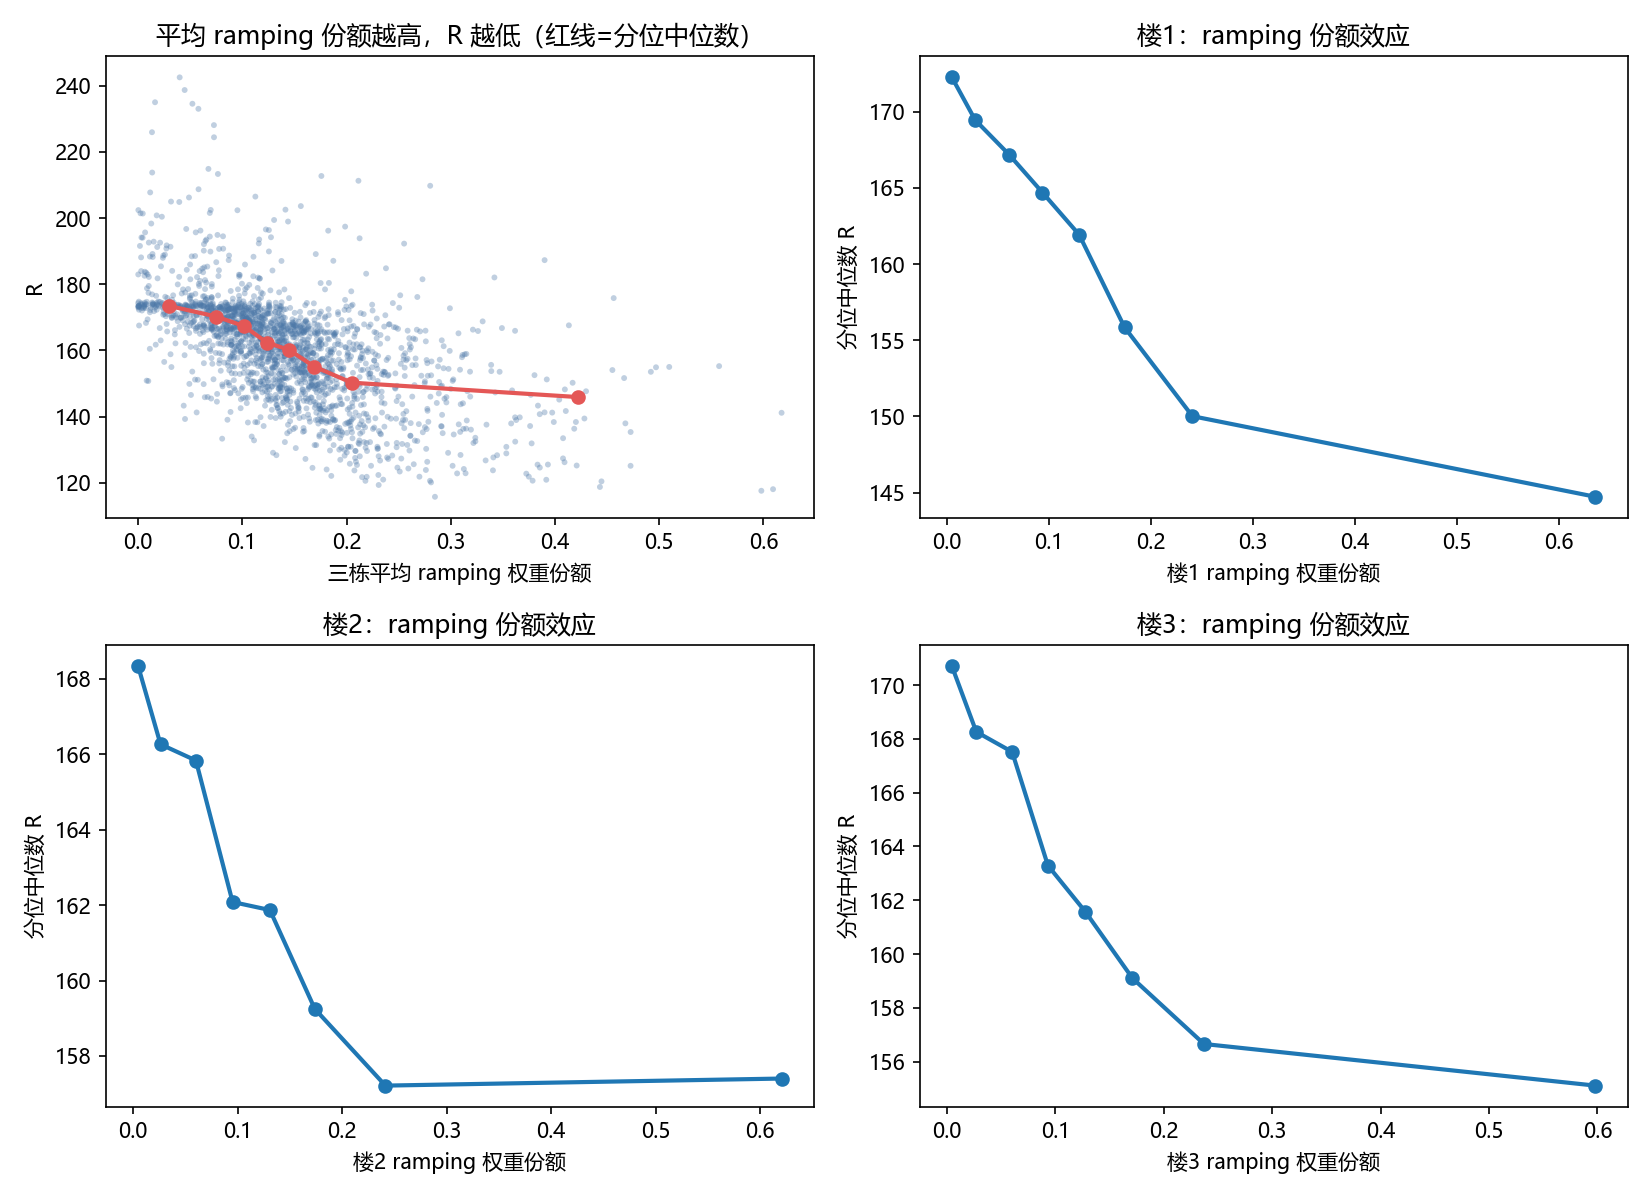

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/fig_off_share_R.png"))


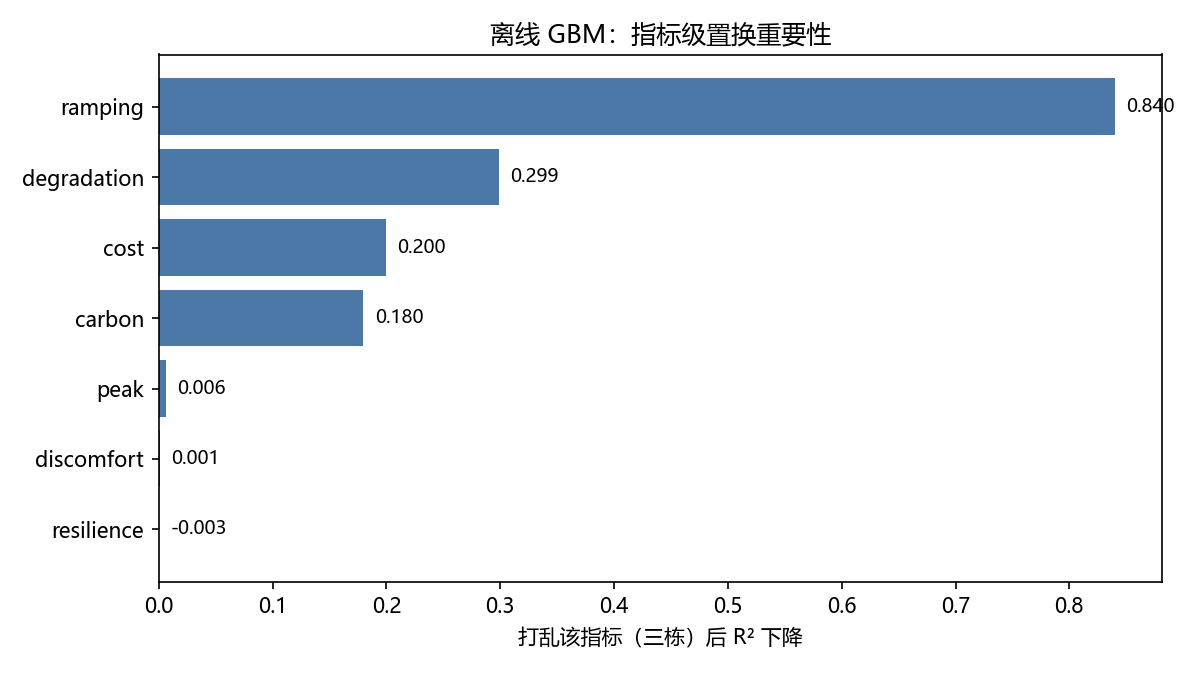

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/fig_off_metric_importance.png"))


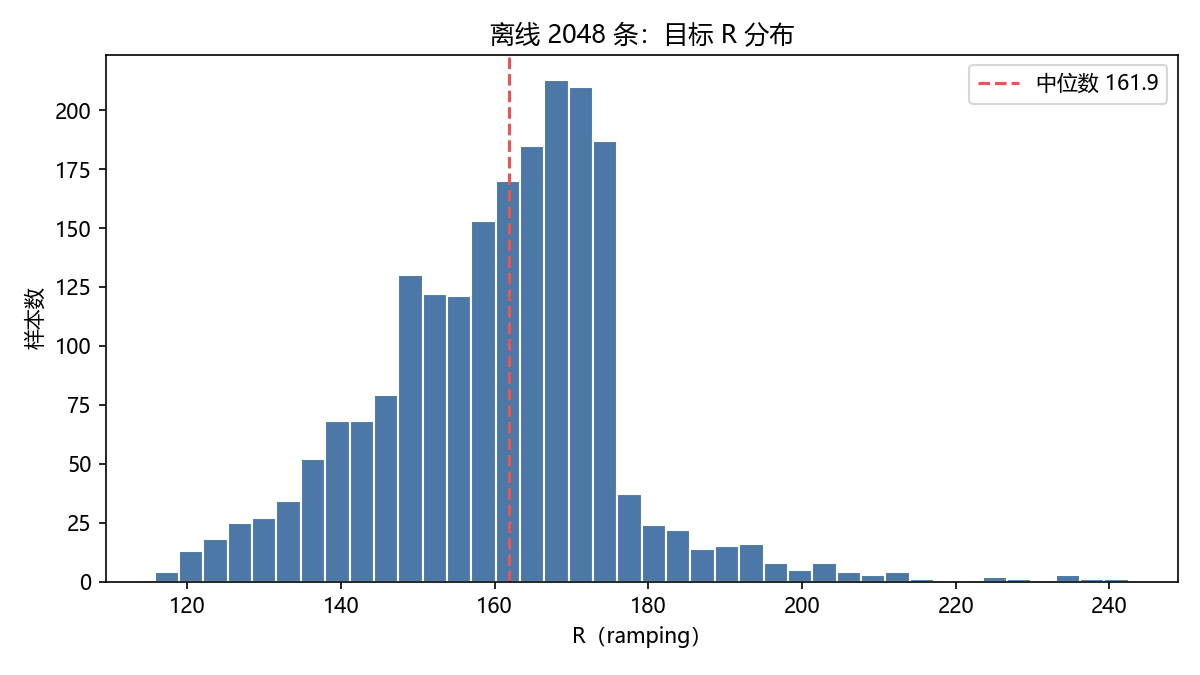

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/fig_off_target_hist.png"))


## 2.2 楼间可加性

**结论：不满足可加性，三栋楼必须联合建模。**

| 模型 | 5 折 CV R² | RMSE |
|---|---|---|
| Ridge（线性可加，21 维） | 0.5143 | 10.975 |
| Ridge + 全部跨楼交互项 | 0.6247 | 9.632 |
| RandomForest（联合 21 维） | 0.7005 | 8.610 |
| HistGradientBoosting（联合 21 维） | **0.7726** | **7.503** |
| 三栋各自 GBM 后相加（可加模型） | 0.2630 | 13.492 |

- 可加模型 R² 仅 0.263，远低于联合模型 0.773；加入跨楼交互项后线性模型从 0.514 提升到 0.625。
- 说明 R 主要来自三栋楼的**联合组合**，不是三栋独立贡献之和。

**建模先验**：T09/T12 用 21 维联合特征；如果为了可解释性要拆模型，必须显式加入跨楼交互项，否则 R² 会掉一半以上。


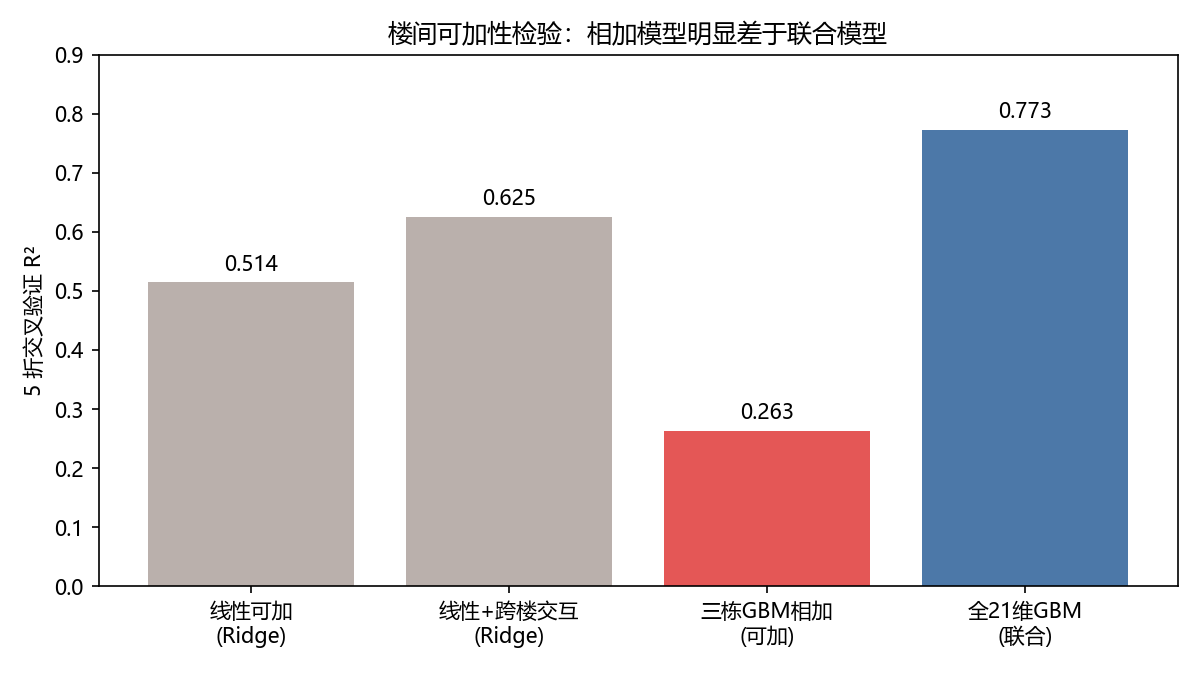

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/fig_off_additivity.png"))


## 2.3 2 号楼低敏感度

**结论：2 号楼单独几乎不携带 R 信息。**

| 楼栋 | GBM 置换重要性（R² 下降） | 单楼 GBM CV R² | 本楼 ramping 份额 Spearman |
|---|---|---|---|
| 楼1 | 0.9087 | 0.4585 | −0.5908 |
| 楼2 | **0.0728** | **−0.1375** | −0.2294 |
| 楼3 | 0.4356 | 0.1506 | −0.3960 |

- 2 号楼单独建模的 CV R² 为负（−0.1375），不如直接预测均值；打乱其 7 个权重只让联合模型 R² 下降 0.073，而楼1 下降 0.909。
- 2 号楼低敏感不等于完全无效：在全正/联合条件下它仍参与组合，但**单独变化很难改变 R**。

**建模先验**：提议预算和特征工程向楼1、楼3 倾斜；楼2 的权重保持保守/均匀，不做重点搜索；模型中对楼2 特征可降权或加正则。


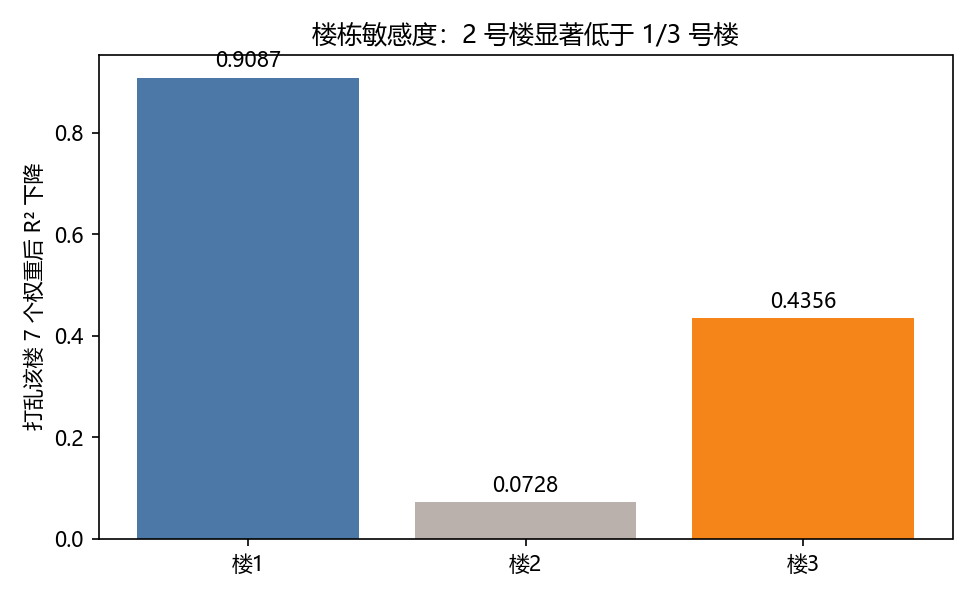

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/fig_off_building_importance.png"))


## 3. 转写为三条可执行建模先验

1. **比例先验**：用每栋楼的 7 维份额作特征；`ramping` 份额是首要杠杆（单调负相关），`degradation`/`cost`/`carbon` 份额是次要正相关杠杆。
2. **联合先验**：三栋楼不可加，统一用 21 维联合模型；任何拆分模型都要显式加跨楼交互项。
3. **敏感度先验**：楼1 > 楼3 >> 楼2；搜索/提议预算按此分配，楼2 不做重点优化。


## 4. 与真实求解器的边界

- 本节全部结论来自 2048 条离线数据，**没有调用真实求解器**，不占用「20 次/人、每次≤50 组」的额度。
- 离线池的 R 范围是 115.765–242.521，与在线求解器量级不同，**离线 R 不能和在线 R 直接比较**。
- 真实求解器只用于 T19 真实演练和 T22 正式提交（由张子木统一发起计分调用）。
- 本地历史上基于真实求解器的 6,568 次调用属于个人预研，**不进入本节证据链**。


## 5. 局限与待验证

- 2048 条是随机/均匀覆盖，无法反映在线响应面的窄平台（例如 7×10⁻⁴ 量级台阶）和单点凹口；这些只能在 T17 回放或极少量真实调用上验证。
- 置换重要性依赖 GBM 模型，不等于因果效应。
- 「楼2 低敏感」是在当前采样范围内成立，在线响应面是否存在同样性质需实测。
- 8 个分位每档仅 256 条，分位中位数有抽样波动；更细的比例效应需在回放器中做控制变量实验。


## 6. 复现清单

| 内容 | 文件 |
|---|---|
| 离线数据 | `train.csv`（2048 行，21 权重列 + `ramping`） |
| 本 notebook | 可直接重跑：数据加载、模型对比、置换重要性 |
| 图 | `figures/fig_off_share_R.png`、`fig_off_metric_importance.png`、`fig_off_building_importance.png`、`fig_off_additivity.png`、`fig_off_target_hist.png` |
| 随机种子 | 数据划分与模型均为 random_state=0；置换 5 折 |
